In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.5/95.5 kB 10.0 MB/s eta 0:00:00


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dice2.v1-dice-2.yolov8.zip to dice2.v1-dice-2.yolov8.zip


In [ ]:
import zipfile

with zipfile.ZipFile("dice2.v1-dice-2.yolov8.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

In [ ]:
!ls -R /content/dice2.v1-dice-2.yolov8 | head -40

ls: cannot access '/content/dice2.v1-dice-2.yolov8': No such file or directory


In [ ]:
!ls /content


data.yaml		    README.roboflow.txt  test	valid
dice2.v1-dice-2.yolov8.zip  sample_data		 train


In [ ]:
!find /content/train/images -type f | wc -l
!find /content/valid/images -type f | wc -l
!find /content/test/images -type f | wc -l

210
60
30


In [ ]:
!cat /content/data.yaml

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['green', 'red', 'yellow']

roboflow:
  workspace: rugved-bairagi
  project: dice2-v0iun
  version: 1
  license: Private
  url: https://app.roboflow.com/rugved-bairagi/dice2-v0iun/1

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
results = model.train(
    data="/content/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.172 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, 

In [ ]:
!ls -lh /content/runs/detect/train/weights/

total 12M
-rw-r--r-- 1 root root 6.0M Oct  3 12:11 best.pt
-rw-r--r-- 1 root root 6.0M Oct  3 12:11 last.pt


In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train/weights/best.pt")

results = model.predict(
    source="/content/test/images",
    conf=0.5,
    save=True
)


image 1/30 /content/test/images/20261001_214744_jpg.rf.83804773cd872c69e2ad5fca50c20934.jpg: 640x640 1 red, 11.9ms
image 2/30 /content/test/images/20261001_214843_jpg.rf.42f5d944ff08ce2cc419cdb28c628d02.jpg: 640x640 1 red, 29.4ms
image 3/30 /content/test/images/20261001_214941_jpg.rf.edbaf96b55081d162c3f5061e4bcfdc8.jpg: 640x640 1 red, 43.3ms
image 4/30 /content/test/images/20261001_214949_jpg.rf.431fe6fca7d420b4ff7e3853b987528d.jpg: 640x640 1 red, 29.2ms
image 5/30 /content/test/images/20261001_215319_jpg.rf.f06e3d27386064c830076213f0d94101.jpg: 640x640 1 red, 27.0ms
image 6/30 /content/test/images/20261001_215510_jpg.rf.8a9a95f1b08ceb92cf005a21a236fa66.jpg: 640x640 1 red, 23.9ms
image 7/30 /content/test/images/20261001_215537_jpg.rf.0345275d401a74ca34a2137d728428f8.jpg: 640x640 1 red, 22.3ms
image 8/30 /content/test/images/20261001_215553_jpg.rf.cd9ab0aed494e9293a1b706177729dcd.jpg: 640x640 1 red, 16.8ms
image 9/30 /content/test/images/20261001_215627_jpg.rf.2c744db312925688a1db9412

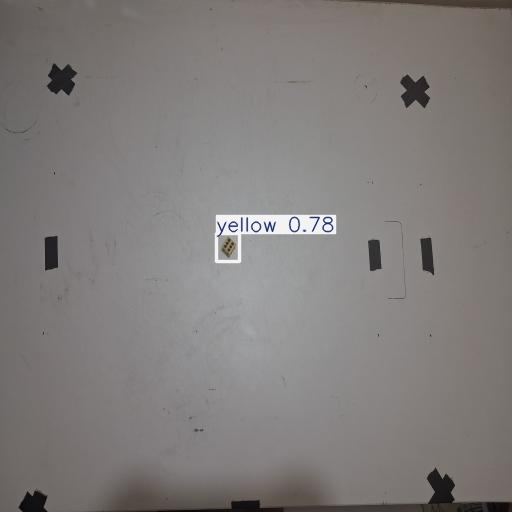

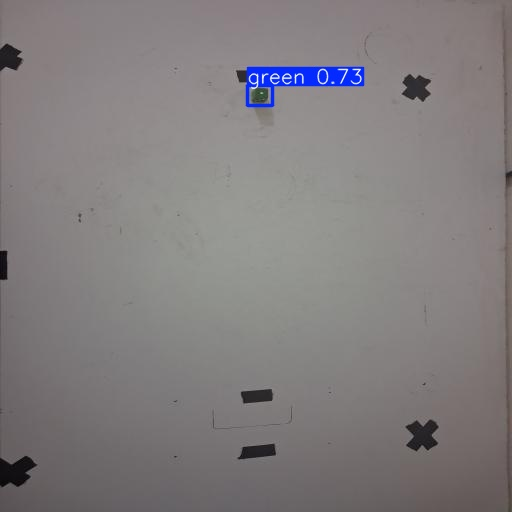

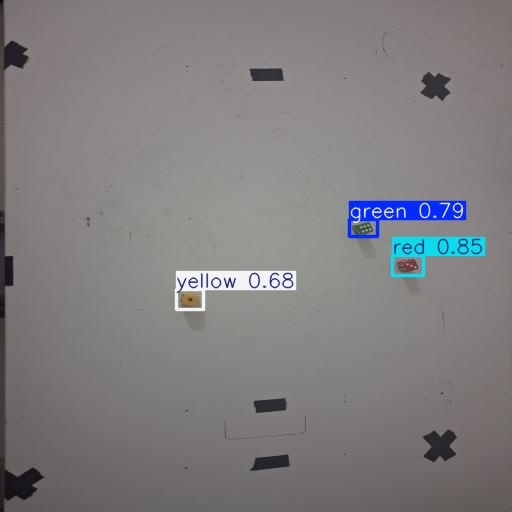

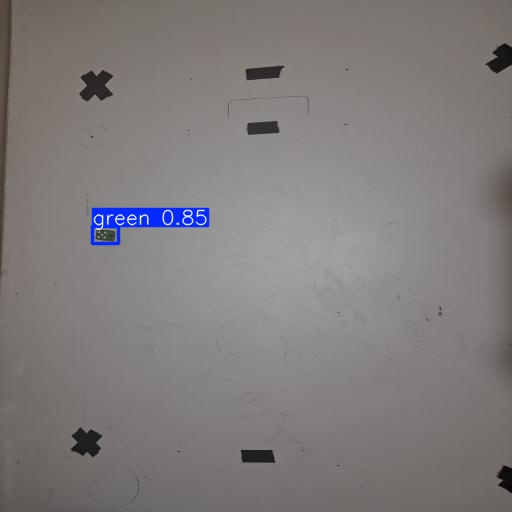

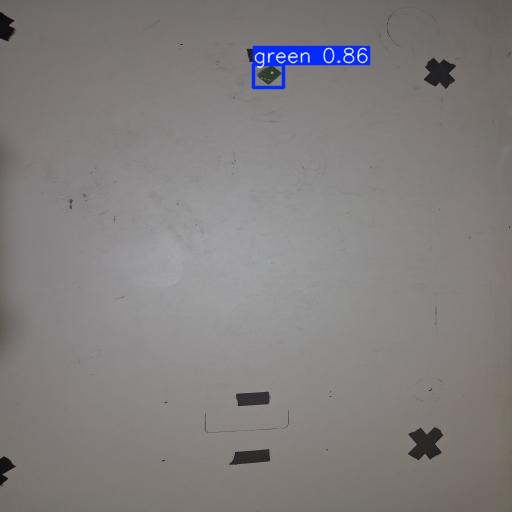

In [ ]:
from IPython.display import Image, display
import glob

images = glob.glob("/content/runs/detect/predict/*.jpg")

for img in images[:5]:
    display(Image(filename=img))

In [ ]:
test_results = model.val(
    data="/content/data.yaml",
    split="test",
    imgsz=640,
    device=0
)

Ultralytics 8.4.172 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 379.1±86.2 MB/s, size: 10.1 KB)
val: Scanning /content/test/labels... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 1.7Kit/s 0.0s
val: New cache created: /content/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.5s/it 2.9s
                   all         30         32      0.988          1      0.995      0.668
                 green         12         12      0.987          1      0.995      0.697
                   red         12         12      0.986          1      0.995      0.629
                yellow          8          8      0.992          1      0.995      0.679
Speed: 11.7ms preprocess, 19.3ms inference, 0.0ms loss, 9.1ms postprocess per image
Results saved to /content

In [ ]:
results = model.predict(
    source="/content/test/images",
    conf=0.5,
    save=True
)

for result in results[:1]:
    print(result.boxes.xyxy)
    print(result.boxes.cls)
    print(result.boxes.conf)


image 1/30 /content/test/images/20261001_214744_jpg.rf.83804773cd872c69e2ad5fca50c20934.jpg: 640x640 1 red, 11.8ms
image 2/30 /content/test/images/20261001_214843_jpg.rf.42f5d944ff08ce2cc419cdb28c628d02.jpg: 640x640 1 red, 11.9ms
image 3/30 /content/test/images/20261001_214941_jpg.rf.edbaf96b55081d162c3f5061e4bcfdc8.jpg: 640x640 1 red, 11.6ms
image 4/30 /content/test/images/20261001_214949_jpg.rf.431fe6fca7d420b4ff7e3853b987528d.jpg: 640x640 1 red, 11.7ms
image 5/30 /content/test/images/20261001_215319_jpg.rf.f06e3d27386064c830076213f0d94101.jpg: 640x640 1 red, 11.7ms
image 6/30 /content/test/images/20261001_215510_jpg.rf.8a9a95f1b08ceb92cf005a21a236fa66.jpg: 640x640 1 red, 11.6ms
image 7/30 /content/test/images/20261001_215537_jpg.rf.0345275d401a74ca34a2137d728428f8.jpg: 640x640 1 red, 11.8ms
image 8/30 /content/test/images/20261001_215553_jpg.rf.cd9ab0aed494e9293a1b706177729dcd.jpg: 640x640 1 red, 11.6ms
image 9/30 /content/test/images/20261001_215627_jpg.rf.2c744db312925688a1db9412

In [ ]:
for result in results[:1]:
    for box in result.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        cls = int(box.cls[0])
        conf = float(box.conf[0])

        cx = (x1 + x2) / 2
        cy = (y1 + y2) / 2

        print(f"Class: {model.names[cls]}")
        print(f"Confidence: {conf:.2f}")
        print(f"Center: ({cx:.1f}, {cy:.1f}) pixels")

Class: red
Confidence: 0.84
Center: (269.8, 218.5) pixels


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp /content/runs/detect/train/weights/best.pt /content/drive/MyDrive/best.pt

In [ ]:
!cp -r /content/runs/detect/train /content/drive/MyDrive/YOLO_training_results